# Lista de Exercícios 3: Aproximação de Funções

#### Disciplina: Aprendizado por Reforço
#### Professor: Luiz Chaimowicz
#### Monitores: Marcelo Lemos e Ronaldo Vieira

---

## Instruções

- ***SUBMISSÕES QUE NÃO SEGUIREM AS INSTRUÇÕES A SEGUIR NÃO SERÃO AVALIADAS.***
- Leia atentamente toda a lista de exercícios e familiarize-se com o código fornecido antes de começar a implementação.
- Os locais onde você deverá escrever suas soluções estão demarcados com comentários `# YOUR CODE HERE` ou `YOUR ANSWER HERE`.
- **Não altere o código fora das áreas indicadas, nem adicione ou remova células. O nome deste arquivo também não deve ser modificado.**
- Antes de submeter, certifique-se de que o código esteja funcionando do início ao fim sem erros.
- Submeta apenas este notebook (*ps3.ipynb*) com as suas soluções no Moodle.
- Prazo de entrega: 30/10/2025. Submissões fora do prazo terão uma penalização de -20% da nota final por dia de atraso.
- Utilize a [documentação do Gymnasium](https://gymnasium.farama.org/) para auxiliar sua implementação.
- Em caso de dúvidas entre em contato pelo fórum "Dúvidas com relação aos exercícios e trabalho de curso" no moodle da Disciplina.

---

## Mountain Car

Mountain Car é um ambiente no qual um agente precisa conduzir um carro até o topo de uma montanha. No entanto, o motor do carro não é potente o suficiente para subir diretamente até o topo. Por isso, o agente precisa aprender a aproveitar o impulso - movendo-se para frente e para trás - para ganhar velocidade suficiente e alcançar o topo.

![](https://gymnasium.farama.org/_images/mountain_car.gif)

O espaço de observação é contínuo e composto por dois valores: a posição e a velocidade do carro. O agente pode escolher entre três ações discretas: acelerar o carro para a esquerda, acelerar para a direita, ou não acelerar. A posição inicial do agente é definida de forma uniformemente aleatória no intervalo $[-0.6, -0.4]$. O episódio se encerra quando o carro atinge o topo da montanha à direita (posição $0.5$) ou quando o limite de 200 passos é atingido. A cada passo, o agente recebe uma penalidade de $-1$, incentivando-o a alcançar o objetivo no menor número possível de passos. Para mais detalhes sobre o ambiente leia a [documentação do gymnasium](https://gymnasium.farama.org/environments/classic_control/mountain_car/).

Devido à natureza contínua do espaço de estados, métodos tabulares não são eficazes no Mountain Car. Assim, é comum o uso de técnicas de aproximação de função para solucionar o problema de forma eficiente. Nesta lista de exercícios, você irá trabalhar com o ambiente descrito acima. Seu objetivo será implementar o algoritmo *Semi-Gradient Episodic Sarsa* com aproximação linear e explorar como diferentes técnicas de construção de features influenciam o desempenho do agente.

## Semi-Gradient Episodic Sarsa

Nesta atividade, você implementará um agente baseado no algoritmo Semi-Gradient Episodic SARSA, utilizando uma **função de valor linear**.

Antes de iniciar sua implementação, analise a interface `FeatureExtractor` fornecida abaixo. Ela será a base para os construtores de features que você implementará na próxima seção. O agente utilizará um objeto com essa interface para extrair features a partir das observações dos estados.

In [71]:
from abc import ABC, abstractmethod

import numpy as np
import gymnasium as gym
import sklearn
import matplotlib.pyplot as plt

In [72]:
class FeatureExtractor(ABC):
    """
    Interface for feature extractors that convert environment states into feature vectors.
    """

    @property
    @abstractmethod
    def feature_size(self):
        """
        Property that returns the size of the feature vector produced by this extractor.

        Returns:
            An integer representing the length of the feature vector.
        """
        pass

    @abstractmethod
    def extract(self, state):
        """
        Converts a raw state into a 1D feature vector.

        Args:
            state: The observation state from the environment.

        Returns:
            The extracted feature vector representation.
        """
        pass

Siga as instruções abaixo para implementar seu agente:

1. Implemente o método `__init__` que inicializa um novo agente. Ele deve receber como parâmetros o espaço de observações, o espaço de ações, um construtor de features (`feature_extractor`), a taxa de aprendizado $\alpha$, o fator de desconto $\gamma$, e o parâmetro de exploração $\varepsilon$. Inicialize os pesos do modelo na variável `self.weights`.
2. Implemente o método `compute_q_values`, que recebe um vetor de features e calcula os *Q-values* de acordo com a entrada.
3. Implemente o método `choose_action`, responsável por escolher uma ação a partir de um estado observado, seguindo a política $\varepsilon$-greedy.
4. Implemente o método `learn`, que atualiza os pesos do agente com base na experiência obtida durante a interação com o ambiente.
5. Implemente o método `train`, que executa o loop de treinamento do algoritmo Sarsa. O ambiente de treinamento e o número de episódios devem ser fornecidos como parâmetros de entrada. O método deve retornar uma lista com a soma das recompensas obtidas ao longo de cada episódio.

In [73]:
class SGESAgent:
    def __init__(self, observation_space, action_space, feature_extractor, alpha, gamma, epsilon):
        self.observation_space = observation_space
        self.action_space = action_space
        self.feature_extractor = feature_extractor
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        
        self.weights = np.zeros((action_space.n, feature_extractor.feature_size))

    def compute_q_values(self, features):
        return np.dot(self.weights, features)

    def choose_action(self, state):
        if np.random.random() < self.epsilon:
            return self.action_space.sample()
        else:
            features = self.feature_extractor.extract(state)
            q_values = self.compute_q_values(features)
            return np.argmax(q_values)

    def learn(self, state, action, reward, next_state, next_action, done):
        features = self.feature_extractor.extract(state)
        q_current = self.compute_q_values(features)[action]

        if done:
            q_next = 0
        else:
            next_features = self.feature_extractor.extract(next_state)
            q_next = self.compute_q_values(next_features)[next_action]
        
        td_target = reward + self.gamma * q_next
        td_error = td_target - q_current
        
        self.weights[action] += self.alpha * td_error * features

    def train(self, env, episodes):
        episode_rewards = []
        for _ in range(episodes):
            state, _ = env.reset()
            action = self.choose_action(state)
            
            total_reward = 0
            done = False
            
            while not done:
                next_state, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated
                total_reward += reward
                
                next_action = self.choose_action(next_state)
                self.learn(state, action, reward, next_state, next_action, done)
                
                state = next_state
                action = next_action
            
            episode_rewards.append(total_reward)
            
        return episode_rewards

In [74]:
# Não altere ou remova esta célula

In [75]:
# Não altere ou remova esta célula

In [76]:
# Não altere ou remova esta célula

In [77]:
# Não altere ou remova esta célula

## Construção de Features

Com o algoritmo do agente pronto, você deverá implementar 3 modelos de construtores de features diferentes:

1. **Identidade**
2. **Tile Coding**
3. **Funções de Base Radial**

### Identidade

6. Implemente o `IdentityFeatureExtractor`, cujo método `extract` apenas retorna a observação de entrada, sem realizar nenhuma operação nela.

In [78]:
class IdentityFeatureExtractor(FeatureExtractor):
    def __init__(self, observation_space):
        self.observation_space = observation_space
        
    @property
    def feature_size(self):
        return np.prod(self.observation_space.shape)
        
    def extract(self, state):
        return state

In [79]:
# Não altere ou remova esta célula

7. Treine um novo agente no ambiente Mountain Car por 200 episódios utilizando o `IdentityFeatureExtractor`. O agente deve ser treinado com os seguintes parâmetros: taxa de aprendizado $\alpha = 0.01$, fator de desconto $\gamma = 0.99$ e parâmetro de exploração $\varepsilon = 0.1$. Armazene os retornos episódicos, obtidos no método `train`, na variável `identity_agent`.

**Nota:** Não se preocupe se o desempenho do agente com o `IdentityFeatureExtractor` for insatisfatório. Ele será utilizado apenas como baseline, permitindo observar o comportamento do agente quando nenhuma transformação é aplicada às observações do ambiente.

In [80]:
env = gym.make("MountainCar-v0")

alpha = 0.01
gamma = 0.99
epsilon = 0.1
episodes = 200
feature_extractor = IdentityFeatureExtractor(env.observation_space)
agent = SGESAgent(
    observation_space=env.observation_space,
    action_space=env.action_space,
    feature_extractor=feature_extractor,
    alpha=alpha,
    gamma=gamma,
    epsilon=epsilon
)
identity_agent = agent.train(env, episodes)

env.close()

mean_return = np.mean(identity_agent)
print(f"Mean Return: {mean_return:.2f}")

last_mean = np.mean(identity_agent[-20:])
print(f"Mean Return of the Last 20 Episodes: {last_mean:.2f}")

Mean Return: -199.57
Mean Return of the Last 20 Episodes: -199.55


In [81]:
# Não altere ou remova esta célula

### Tile Coding

8. Implemente o `TileCodingFeatureExtractor`, cujo método `extract` gera um vetor de features utilizando a técnica de *tile coding*. A quantidade de tilings a ser gerada é definida pelo parâmetro `num_tilings`, enquanto a quantidade de divisões por dimensão em cada tiling é definida pelo parâmetro `tiles_per_dim`. Ambos valores são fornecidos ao construtor da classe. Por exemplo: um `TileCodingFeatureExtractor` com `num_tilings = 3` e `tiles_per_dim = 2` deve gerar 3 tilings, cada um dividindo o espaço em uma grade de tamanho 2$\times$2.

In [82]:
class TileCodingFeatureExtractor(FeatureExtractor):
    def __init__(self, observation_space, num_tilings, tiles_per_dim):
        self.observation_space = observation_space
        self.num_tilings = num_tilings
        self.tiles_per_dim = tiles_per_dim  
        self.num_dims = observation_space.shape[0]
        
        self.low = observation_space.low
        self.high = observation_space.high
        
        self.tile_widths = (self.high - self.low) / self.tiles_per_dim
        
        self.tiles_per_tiling = self.tiles_per_dim ** self.num_dims
        
        self._feature_size = self.tiles_per_tiling * self.num_tilings
        
        self.dims = [self.tiles_per_dim] * self.num_dims
        
        self.tiling_origins = np.zeros((num_tilings, self.num_dims))
        
        stagger_vector = np.array([1 + 2 * i for i in range(self.num_dims)])
        
        for t in range(num_tilings):
            displacement = (t / num_tilings) * self.tile_widths * stagger_vector
            self.tiling_origins[t] = self.low - displacement

    @property
    def feature_size(self):
        return self._feature_size

    def extract(self, state):
        feature_vector = np.zeros(self.feature_size)
        
        for t in range(self.num_tilings):
            origin = self.tiling_origins[t]
            
            coords = np.floor((state - origin) / self.tile_widths).astype(int)
            
            tiling_index = np.ravel_multi_index(
                coords,
                dims=self.dims,
                mode='wrap'
            )
            
            global_index = t * self.tiles_per_tiling + tiling_index
            
            feature_vector[global_index] = 1.0
            
        return feature_vector

In [83]:
# Não altere ou remova esta célula

9. Treine um novo agente no ambiente Mountain Car por 200 episódios utilizando o `TileCodingFeatureExtractor`. O agente deve ser treinado com os seguintes parâmetros: taxa de aprendizado $\alpha = 0.01$, fator de desconto $\gamma = 0.99$ e parâmetro de exploração $\varepsilon = 0.1$. Para os parâmetros `num_tilings` e `tiles_per_dim`, utilize os valores que proporcionarem os melhores resultados. Armazene os retornos episódicos, obtidos no método `train`, na variável `tile_agent`.

In [84]:
env = gym.make("MountainCar-v0")

alpha = 0.01
gamma = 0.99
epsilon = 0.1
episodes = 200

num_tilings = 8
tiles_per_dim = 8

tile_extractor = TileCodingFeatureExtractor(env.observation_space, 
                                            num_tilings=num_tilings, 
                                            tiles_per_dim=tiles_per_dim)

agent = SGESAgent(observation_space=env.observation_space,
                  action_space=env.action_space,
                  feature_extractor=tile_extractor,
                  alpha=alpha,
                  gamma=gamma,
                  epsilon=epsilon)

tile_agent = agent.train(env, episodes)

env.close()

mean_return = np.mean(tile_agent)
print(f"Mean Return: {mean_return:.2f}")

last_mean = np.mean(tile_agent[-20:])
print(f"Mean Return of the Last 20 Episodes: {last_mean:.2f}")

Mean Return: -197.00
Mean Return of the Last 20 Episodes: -186.85


In [85]:
# Não altere ou remova esta célula

### Funções de Base Radial

10. Implemente o `RBFFeatureExtractor`, cujo método `extract` gera um conjunto de features baseadas em *Radial Basis Functions*. A quantidade total de componentes a ser gerada é definida pelo parâmetro `n_components`, fornecido ao construtor da classe. Utilize a biblioteca *scikit-learn* (sklearn) para auxiliar sua implementação.

**Importante:** Você pode combinar RBFs com diferentes parâmetros para capturar melhor dinâmicas complexas do ambiente e potencialmente melhorar o desempenho do agente. Experimente diferentes configurações para identificar as combinações que produzem os melhores resultados de aprendizado. Normalizar o vetor de entrada também pode facilitar o aprendizado.

In [86]:
from sklearn.preprocessing import StandardScaler
from sklearn.kernel_approximation import RBFSampler

class RBFFeatureExtractor(FeatureExtractor):
    def __init__(self, observation_space, n_components):
        self.observation_space = observation_space
        self.n_components = n_components
        
        env = gym.make("MountainCar-v0")
        observation_samples = np.array(
            [env.observation_space.sample() for _ in range(10000)]
        )
        env.close()

        self.scaler = StandardScaler()
        self.scaler.fit(observation_samples)
        
        scaled_samples = self.scaler.transform(observation_samples)

        gammas = [0.5, 1.0, 2.0] 
        n_per_gamma = self.n_components // len(gammas)
        
        self.samplers = []
        for gamma in gammas:
            sampler = RBFSampler(n_components=n_per_gamma, gamma=gamma, random_state=42)
            
            sampler.fit(scaled_samples)
            self.samplers.append(sampler)
            
        self._feature_size = n_per_gamma * len(gammas)

    @property
    def feature_size(self):
        return self._feature_size

    def extract(self, state):
        
        state_2d = state.reshape(1, -1)
        
        scaled_state = self.scaler.transform(state_2d)
        
        all_features = []
        for sampler in self.samplers:
            features = sampler.transform(scaled_state)
            all_features.append(features)
            
        combined_features = np.concatenate(all_features, axis=1)
        
        return combined_features.flatten()

In [87]:
# Não altere ou remova esta célula

11. Treine um novo agente no ambiente Mountain Car por 200 episódios utilizando o `RBFFeatureExtractor` com 100 componentes. O agente deve ser treinado com os seguintes parâmetros: taxa de aprendizado $\alpha = 0.01$, fator de desconto $\gamma = 0.99$ e parâmetro de exploração $\varepsilon = 0.1$. Armazene os retornos episódicos, obtidos no método `train`, na variável `rbf_agent`.

In [88]:
env = gym.make("MountainCar-v0")

alpha = 0.01
gamma = 0.99
epsilon = 0.1
episodes = 200
n_components = 100 

rbf_extractor = RBFFeatureExtractor(env.observation_space, 
                                    n_components=n_components)

agent = SGESAgent(observation_space=env.observation_space,
                  action_space=env.action_space,
                  feature_extractor=rbf_extractor,
                  alpha=alpha,
                  gamma=gamma,
                  epsilon=epsilon)

rbf_agent = agent.train(env, episodes)

env.close()

mean_return = np.mean(rbf_agent)
print(f"Mean Return: {mean_return:.2f}")

last_mean = np.mean(rbf_agent[-20:])
print(f"Mean Return of the Last 20 Episodes: {last_mean:.2f}")

Mean Return: -180.45
Mean Return of the Last 20 Episodes: -184.85


In [89]:
assert 'rbf_agent' in vars()

## Análise

12. Utilize a biblioteca matplotlib para construir um gráfico comparativo dos retornos episódicos obtidos pelos agentes utilizando cada um dos construtores de features implementados. Utilize as variáveis `identiy_agent`, `tile_agent` e `rbf_agent` obtidas nos exercícios anteriores. No eixo X, represente os episódios; no eixo Y, o retorno acumulado por episódio. Caso seja necessário, aplique uma média movel para suavizar as curvas e deixar as tendências mais evidentes. Inclua título, legendas e rótulos de eixos apropriados para facilitar a interpretação. Se utilizar algum tipo de suavização, indique claramente no gráfico qual o método aplicado.

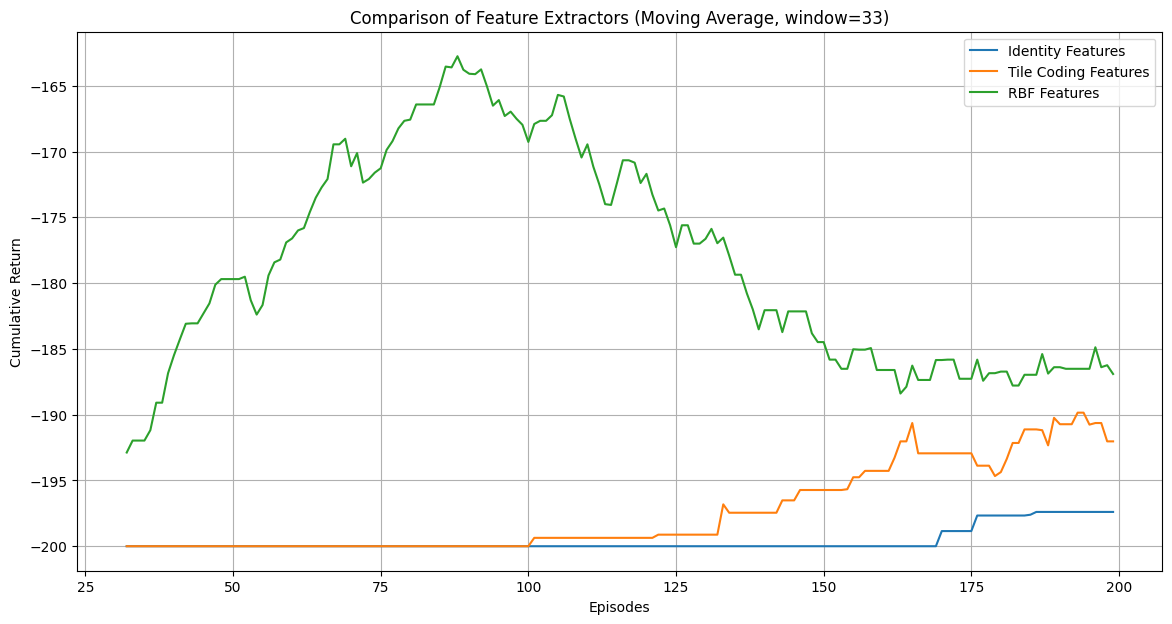

In [90]:
def moving_average(data, window_size):
    """Calculates the moving average of a list or array."""
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

window = 33

identity_smoothed = moving_average(identity_agent, window)
tile_smoothed = moving_average(tile_agent, window)
rbf_smoothed = moving_average(rbf_agent, window)

episodes_axis = np.arange(window - 1, len(identity_agent))

plt.figure(figsize=(14, 7))
plt.plot(episodes_axis, identity_smoothed, label='Identity Features')
plt.plot(episodes_axis, tile_smoothed, label='Tile Coding Features')
plt.plot(episodes_axis, rbf_smoothed, label='RBF Features')

plt.title(f'Comparison of Feature Extractors (Moving Average, window={window})')
plt.xlabel('Episodes')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True)
plt.show()

13. Explique por que a modelagem do construtor de features pode ser crucial para o desempenho de um agente que utiliza aproximação de função.

A modelagem do construtor de features é crucial porque um agente com aproximação de função linear, como o implementado, só consegue aprender relações lineares entre as features e os valores das ações. Se o problema for não-linear (como o Mountain Car, onde ir para trás pode ser benéfico), o agente falhará se receber os estados brutos. O construtor de features, portanto, tem a tarefa de transformar o espaço de estados original em uma nova representação, onde a função de valor possa ser aproximada por um modelo linear.

Os resultados obtidos demonstram isso. O Identity Feature falhou, pois o modelo linear não conseguiu capturar a complexidade do problema. Por outro lado, o Tile Coding e o RBF tiveram sucesso porque ambos realizam essa transformação não-linear. Eles agrupam estados contínuos semelhantes em representações de features parecidas, o que permite a generalização. O aprendizado obtido em um estado específico é automaticamente estendido para outros estados vizinhos, permitindo que o agente aprenda uma política eficaz.

14. Quais critérios devem guiar a escolha dos modelos e da quantidade de features a serem utilizadas na construção do espaço de features?

A escolha do modelo e da quantidade de features é guiada por um balanço fundamental entre discriminação e generalização, além de restrições práticas. Precisamos de features suficientes para que o agente possa discriminar estados que exigem ações distintas. Se usarmos poucas features, como uma grade única de 2x2, estados muito diferentes (ex: "indo rápido para a esquerda" vs. "indo devagar para a direita") podem cair na mesma feature, tornando impossível para o agente aprender a política correta. Por outro lado, se usarmos features demais, o agente perde a capacidade de generalizar: o que ele aprende sobre um estado não é transferido para estados vizinhos, tornando o aprendizado extremamente lento ou levando ao overfitting.

O modelo (Identity Features, Tile Coding, RBF) também deve ser levado em consideração: 
* Identity Feature falha porque não oferece a discriminação correta, ele fornece features "erradas" (posição, velocidade) cuja relação com o valor Q não é linear. O problema não é linearmente separável com esses dados, e o agente não consegue discriminar um bom estado de um ruim.

* Modelos como Tile Coding e RBF criam essa discriminação ao transformar o espaço não-linear em áreas que um modelo linear pode entender.

    - Tile Coding é ótimo para generalização localizada em problemas de baixa dimensão;
    - RBF oferece uma generalização mais suave e pode se adaptar melhor a dimensões mais altas. 
        
Critérios práticos como custo computacional e memória também são importantes, pois o número de features impacta diretamente o tamanho da matriz de pesos e a velocidade de cada passo de aprendizado.